# Support-set diagnostics (steps 1–3)

**Step 1:** one logged Ramen run per dataset, from `log_support.py` using `src/methods/RamenLog.py`. Its predictions are identical to Ramen's. Per sample it stores the zero-shot probabilities, the adapted prediction, the label and the domain, plus the support set: stream ids, queue labels and $\alpha_{ij}$.

**Step 2:** four numbers: (1) transition table, (2) top-$m$ recall of zero-shot CLIP and error concentration, (3) support-set label purity, (4) support-set domain purity. A cache-health view is added because Ramen stores cache priorities in fp16 (see §0).

**Step 3:** `pick_branch` evaluates each row of the decision table. Its thresholds are explicit arguments:
1. *wrong → same wrong* is the largest cell after *right → right*, **and** top-$m$ recall − top-1 ≥ 15 pts ($m$ = 5, or 3 for CIFAR-10, where top-5 is half the classes) → candidate-set entropy.
2. α-weighted label purity < 50% → contamination-aware weighting.
3. Contrast and fog domain lift both < ½ × the median over corruptions → change the retrieval embedding.
4. ≥ 50% of harmful flips have zero-shot margin > 0.5 → gated output.
5. Otherwise → normalized SGD ablation.

*Right → right* is the largest cell whenever zero-shot is decent, so row 1 compares the error cells.

In [1]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')

import pandas as pd
from IPython.display import display
from ramen_analysis import make_experiment
import support_analysis as S

pd.set_option('display.width', 200)

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATASETS = ['CIFAR10C', 'CIFAR100C']
exps, sls = {}, {}
for d in DATASETS:
    exps[d] = make_experiment(d).load()
    exps[d].evaluate()
    exps[d].run('RamenLog')   # cached by log_support.py
    sls[d] = S.SupportLog(exps[d])

CIFAR10C: 15 corruptions x 10000 images, 10 classes, model=clip_vitbase32, mode=mixed
NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl
RamenLog: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR10C_clip_vitbase32_mixed_nall_bs100_s0_RamenLog.pkl
CIFAR100C: 15 corruptions x 10000 images, 100 classes, model=clip_vitbase16, mode=mixed
NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR100C_clip_vitbase16_mixed_nall_bs100_s0_NoAdapt.pkl
Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR100C_clip_vitbase16_mixed_nall_bs100_s0_Ramen.pkl
RamenLog: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/CIFAR100C

## 0. Cache health
Ramen stores each entry's priority (its stream counter) in **fp16**. Above 2048 the counter loses integer precision, and from 65,520 on it is `inf`. A queue that is full of `inf` entries never accepts another sample, because `inf > inf` is false. The table shows the share of queries the cache accepted, and the α-weighted age of the support set (how many samples ago its entries arrived), along the stream.

CIFAR10C


,inserted %,alpha-weighted age of support,Ramen acc %,zero-shot acc %,Ramen gain
stream position,,,,,
0-10%,100.00,3620.58,71.75,61.44,10.31
10-20%,100.00,10966.36,72.88,61.74,11.14
20-30%,100.00,18237.32,72.99,61.37,11.61
30-40%,100.00,25210.11,72.47,61.27,11.20
40-50%,100.00,31703.98,72.47,61.17,11.30
50-60%,100.00,36443.97,72.91,61.40,11.51
60-70%,100.00,37921.77,72.18,61.07,11.11
70-80%,82.11,39821.21,72.85,61.81,11.03
80-90%,80.61,41782.50,72.47,61.27,11.21


CIFAR100C


,inserted %,alpha-weighted age of support,Ramen acc %,zero-shot acc %,Ramen gain
stream position,,,,,
0-10%,100.00,3655.43,44.30,36.63,7.67
10-20%,100.00,10800.00,45.73,37.05,8.67
20-30%,100.00,17559.90,46.11,37.27,8.85
30-40%,100.00,23762.71,46.66,37.32,9.34
40-50%,100.00,28859.66,45.92,36.85,9.07
50-60%,98.78,33238.10,46.36,37.18,9.18
60-70%,85.66,37258.94,46.55,37.36,9.19
70-80%,64.65,41771.25,46.53,37.30,9.23
80-90%,43.17,47767.36,45.79,36.63,9.16


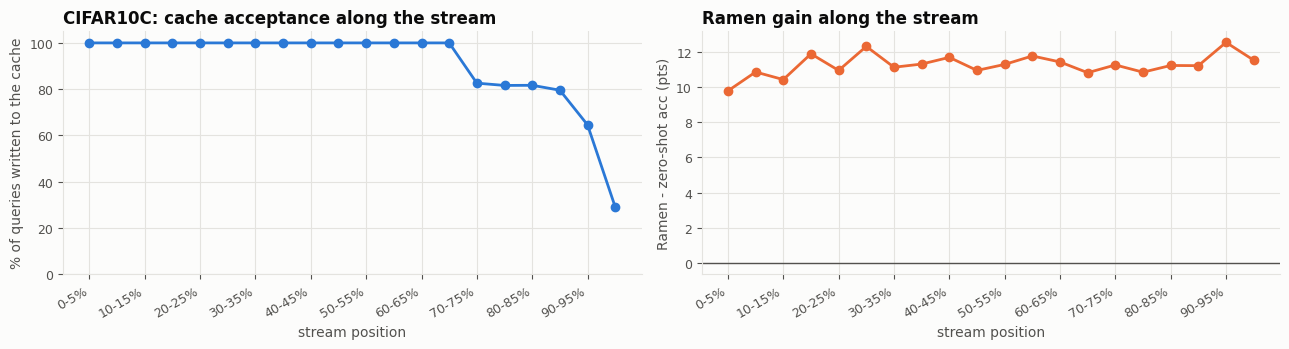

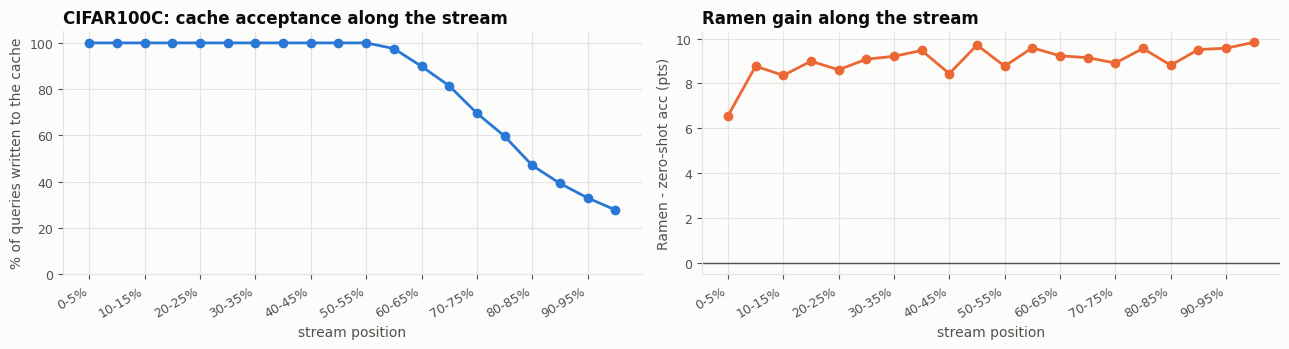

In [3]:
for d in DATASETS:
    print(d)
    display(S.cache_health(sls[d]))
    S.plot_cache_health(sls[d]);

## 1. Transition table
Zero-shot (pretrained weights, Ramen's own step-1 prediction) vs Ramen's adapted prediction, as % of samples.

In [4]:
pd.concat({d: S.transition_table(sls[d]) for d in DATASETS}, axis=1)

CIFAR10C        CIFAR100C       
                            %      n         %      n
cell                                                 
right -> right          55.70  83552     32.56  48843
right -> wrong           5.67   8500      4.53   6792
wrong -> right          16.91  25364     13.53  20301
wrong -> same wrong     12.00  17998     20.20  30300
wrong -> other wrong     9.72  14586     29.18  43764

In [5]:
for d in DATASETS:
    print(d)
    display(S.transition_table(sls[d], by_domain=True))

CIFAR10C


cell,right -> right,right -> wrong,wrong -> right,wrong -> same wrong,wrong -> other wrong
gaussian_noise,30.37,8.25,30.47,11.35,19.56
shot_noise,34.40,8.18,28.74,11.52,17.16
impulse_noise,33.94,8.82,22.33,15.56,19.35
defocus_blur,66.69,5.95,10.43,10.93,6.00
glass_blur,38.68,5.25,25.33,14.81,15.93
motion_blur,63.26,3.43,14.29,13.52,5.50
zoom_blur,67.42,4.30,11.85,11.38,5.05
snow,69.21,4.55,11.44,9.16,5.64
frost,70.52,5.22,9.64,9.32,5.30
fog,63.04,5.87,14.89,8.81,7.39


CIFAR100C


cell,right -> right,right -> wrong,wrong -> right,wrong -> same wrong,wrong -> other wrong
gaussian_noise,18.52,4.33,11.85,22.08,43.22
shot_noise,20.10,4.30,11.88,22.28,41.44
impulse_noise,26.45,3.12,16.49,23.88,30.06
defocus_blur,38.71,4.87,13.89,20.06,22.47
glass_blur,16.27,3.88,12.68,21.75,45.42
motion_blur,38.75,4.84,13.63,19.40,23.38
zoom_blur,43.76,4.86,11.98,20.06,19.34
snow,43.75,5.18,11.55,18.83,20.69
frost,44.66,5.79,9.74,20.03,19.78
fog,37.28,4.46,15.56,18.10,24.60


## 2. Top-$m$ recall of zero-shot CLIP, and error concentration
Error concentration is the share of each class's zero-shot errors that land in its 3 most frequent wrong classes.

In [6]:
for d in DATASETS:
    print(d)
    display(S.topm_recall(sls[d]))
    ec = S.error_concentration(sls[d])
    print(f"error-weighted share of errors in each class's top-3 wrong classes: {ec.attrs['error-weighted share %']:.1f}%")
    display(ec.head(10))

CIFAR10C


,top-1,top-2,top-3,top-5,top-10
gaussian_noise,38.69,58.34,69.24,82.28,100.0
shot_noise,42.62,61.43,71.17,83.57,100.0
impulse_noise,42.79,61.20,72.67,87.78,100.0
defocus_blur,72.64,86.13,91.88,97.23,100.0
glass_blur,43.98,60.46,70.72,81.85,100.0
motion_blur,66.71,82.75,89.23,95.92,100.0
zoom_blur,71.73,86.80,92.18,97.08,100.0
snow,73.73,86.54,91.76,97.12,100.0
frost,75.74,87.95,92.85,97.27,100.0
fog,68.95,83.24,89.40,96.22,100.0


error-weighted share of errors in each class's top-3 wrong classes: 75.2%


,errors,share in top-3 wrong %,top wrong classes
class,,,
deer,8004,68.2,"bird, frog, horse"
truck,7207,68.2,"automobile, ship, bird"
cat,7159,82.7,"bird, dog, frog"
frog,6709,84.0,"bird, cat, dog"
dog,6283,83.0,"bird, cat, frog"
airplane,5072,81.9,"bird, ship, horse"
ship,4684,82.0,"airplane, bird, automobile"
bird,4517,62.9,"frog, dog, deer"
horse,4328,74.1,"dog, bird, deer"


CIFAR100C


,top-1,top-2,top-3,top-5,top-10
gaussian_noise,22.84,31.71,37.85,45.77,56.40
shot_noise,24.36,33.82,40.07,47.52,59.38
impulse_noise,29.57,39.72,46.37,54.53,65.14
defocus_blur,43.60,56.80,64.05,71.66,80.56
glass_blur,20.15,27.95,33.88,41.52,54.27
motion_blur,43.63,55.77,62.59,70.32,78.84
zoom_blur,48.65,61.65,68.41,75.85,83.87
snow,48.96,61.60,68.01,75.02,83.08
frost,50.43,63.83,70.34,77.13,84.97
fog,41.75,54.88,61.81,69.01,78.20


error-weighted share of errors in each class's top-3 wrong classes: 36.5%


,errors,share in top-3 wrong %,top wrong classes
class,,,
crocodile,1460,20.2,"worm, mouse, skunk"
ray,1457,32.7,"shark, flatfish, sea"
porcupine,1443,26.2,"mouse, shrew, beaver"
lobster,1433,23.1,"worm, sweet_pepper, mouse"
leopard,1410,26.7,"fox, wolf, lion"
caterpillar,1346,43.5,"worm, willow_tree, trout"
tiger,1331,31.8,"fox, lion, wolf"
otter,1311,20.5,"beaver, mouse, worm"
bed,1311,29.8,"chair, keyboard, lamp"


## 3. Support-set label purity
The share of $\mathbb{S}_i$ whose true label equals its queue label, i.e. the pseudo-label its entropy gradient pushes towards. *own-queue* restricts this to queue $\hat y_i$. Zero-shot accuracy is shown alongside for reference, since the queue labels *are* zero-shot pseudo-labels.

In [7]:
for d in DATASETS:
    print(d)
    display(S.label_purity(sls[d]))

CIFAR10C


,purity %,alpha-weighted purity %,own-queue purity %,own-queue alpha-weighted purity %,zero-shot acc %
gaussian_noise,49.46,53.50,38.54,41.92,38.62
shot_noise,49.48,53.99,41.90,45.48,42.58
impulse_noise,46.95,53.10,41.13,45.00,42.76
defocus_blur,55.29,67.66,72.96,77.79,72.64
glass_blur,47.37,54.63,48.11,53.10,43.93
motion_blur,54.31,66.36,69.78,74.56,66.69
zoom_blur,56.09,68.45,73.26,77.88,71.72
snow,56.60,69.60,75.03,79.52,73.76
frost,56.86,69.93,76.08,80.42,75.74
fog,52.95,64.89,68.54,73.13,68.91


CIFAR100C


,purity %,alpha-weighted purity %,own-queue purity %,own-queue alpha-weighted purity %,zero-shot acc %
gaussian_noise,28.86,39.53,23.58,26.08,22.85
shot_noise,28.88,39.90,24.42,27.11,24.40
impulse_noise,39.54,54.99,29.97,33.76,29.57
defocus_blur,31.84,51.82,46.62,50.01,43.58
glass_blur,29.89,41.92,21.89,24.40,20.15
motion_blur,30.62,49.34,46.47,49.49,43.59
zoom_blur,31.60,51.91,50.84,54.37,48.62
snow,33.26,53.43,50.69,54.64,48.93
frost,33.42,54.49,52.63,56.16,50.45
fog,30.07,48.89,43.15,46.81,41.74


## 4. Support-set domain purity
The share of $\mathbb{S}_i$ that comes from the query's own corruption. `lift` = purity / that corruption's share of all retrieved entries, so 1 means retrieval ignores the corruption. Focus (bold): contrast, fog, defocus_blur, elastic_transform.

In [8]:
for d in DATASETS:
    print(d)
    t = S.domain_purity(sls[d])
    display(t.style.apply(lambda r: ['font-weight: bold' if r.name in S.FOCUS_DOMAINS else '' for _ in r], axis=1).format('{:.2f}'))

CIFAR10C


,purity %,alpha-weighted purity %,chance %,lift,alpha-weighted lift
gaussian_noise,52.16,53.87,7.96,6.56,6.77
shot_noise,49.10,51.37,8.13,6.04,6.32
impulse_noise,94.55,96.18,6.69,14.13,14.37
defocus_blur,29.26,34.23,7.25,4.03,4.72
glass_blur,53.72,55.60,7.52,7.14,7.39
motion_blur,24.51,28.81,6.82,3.59,4.22
zoom_blur,25.69,31.56,6.81,3.77,4.63
snow,30.57,35.44,7.32,4.17,4.84
frost,26.28,32.74,4.97,5.29,6.59
fog,33.99,41.77,6.61,5.14,6.32


CIFAR100C


,purity %,alpha-weighted purity %,chance %,lift,alpha-weighted lift
gaussian_noise,48.87,51.04,6.95,7.03,7.35
shot_noise,44.15,48.60,6.50,6.79,7.48
impulse_noise,81.25,91.45,6.18,13.14,14.79
defocus_blur,36.03,42.91,6.48,5.56,6.62
glass_blur,41.01,43.34,7.29,5.63,5.95
motion_blur,23.88,29.31,7.43,3.21,3.94
zoom_blur,25.57,34.69,6.45,3.96,5.38
snow,32.76,38.08,9.71,3.37,3.92
frost,28.43,37.49,6.27,4.53,5.98
fog,26.50,41.91,5.36,4.94,7.82


## Step 3: which branch?

In [9]:
for d in DATASETS:
    print(d)
    display(S.pick_branch(sls[d]))

CIFAR10C


,fix,evidence,fires
row,,,
1,candidate-set entropy H_m on top-3 classes,largest error cell = 'wrong -> right' (16.9%);...,False
2,contamination-aware weighting / retrieval,alpha-weighted label purity 63.0% (low < 50.0%),False
3,change retrieval embedding / distance for cont...,"lift contrast 11.10, fog 6.32, median 6.59",False
4,gated output (keep zero-shot when margin > tau...,8.5% of 8500 harmful flips have margin > 0.5,False
5,normalized SGD instead of SignSGD (ablation),no other row fires,True


CIFAR100C


,fix,evidence,fires
row,,,
1,candidate-set entropy H_m on top-5 classes,largest error cell = 'wrong -> other wrong' (2...,False
2,contamination-aware weighting / retrieval,alpha-weighted label purity 48.8% (low < 50.0%),True
3,change retrieval embedding / distance for cont...,"lift contrast 11.76, fog 7.82, median 6.78",False
4,gated output (keep zero-shot when margin > tau...,1.6% of 6792 harmful flips have margin > 0.5,False
5,normalized SGD instead of SignSGD (ablation),no other row fires,False
